In [168]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from ics26_rosenbrock import RESULTS_DIR

In [169]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

shifted_gaussians_with_ac_v1_hessian_informed_experiments
quadratic_v1_hessian_informed_split_experiments_error_split_criteria
quadratic_v1_hessian_informed_split_experiments
shifted_gaussians_with_ac_v1_hessian_informed_error_split_experiments
rosenbrock_convergence_v1_hessian_informed_experiments
rosenbrock_convergence_v1_hessian_informed_error_splitting_experiments


In [170]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Gaussian

In [171]:
gaussian_dir = ICS26_DIR / "shifted_gaussians_with_ac_v1_hessian_informed_experiments"
csv_path = gaussian_dir / "summary.csv"

df_g = pd.read_csv(csv_path)

In [172]:
def plot_error_with_log_log_fit(df, error_col1, error_col2, title1, title2):
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue="dim",
        style="USE_HESSIAN_INFORMED_SPLIT",
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for use_hessian in df["USE_HESSIAN_INFORMED_SPLIT"].unique():
            subset = df[
                (df["dim"] == dim) & (df["USE_HESSIAN_INFORMED_SPLIT"] == use_hessian)
            ]
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (Hessian-informed: {use_hessian}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue="dim",
        style="USE_HESSIAN_INFORMED_SPLIT",
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for use_hessian in df["USE_HESSIAN_INFORMED_SPLIT"].unique():
            subset = df[
                (df["dim"] == dim) & (df["USE_HESSIAN_INFORMED_SPLIT"] == use_hessian)
            ]
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (Hessian-informed: {use_hessian}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

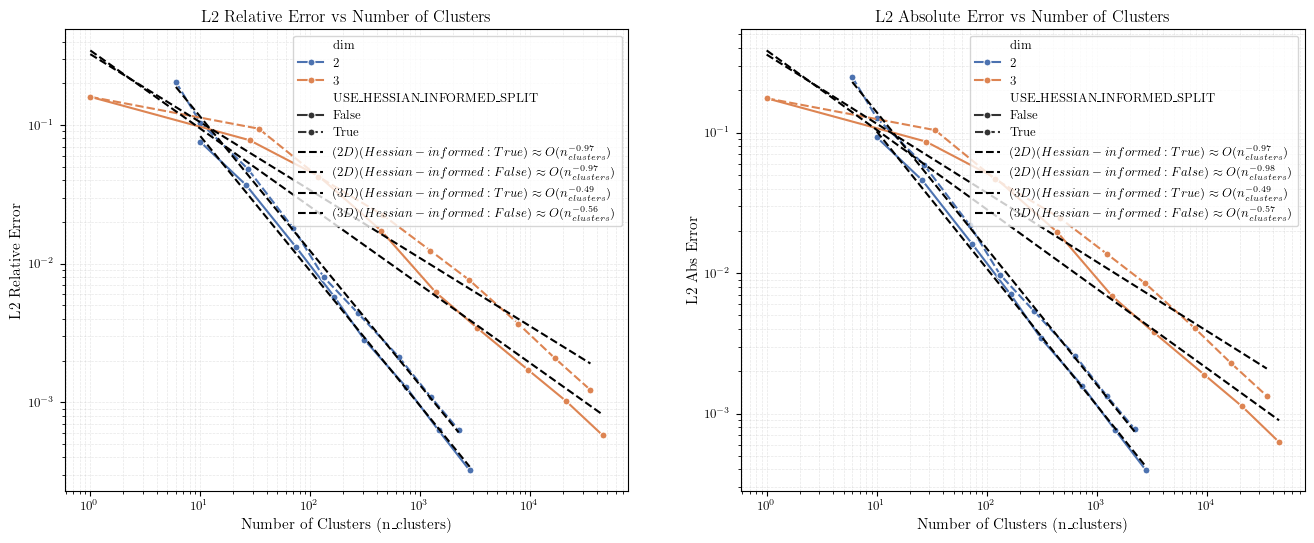

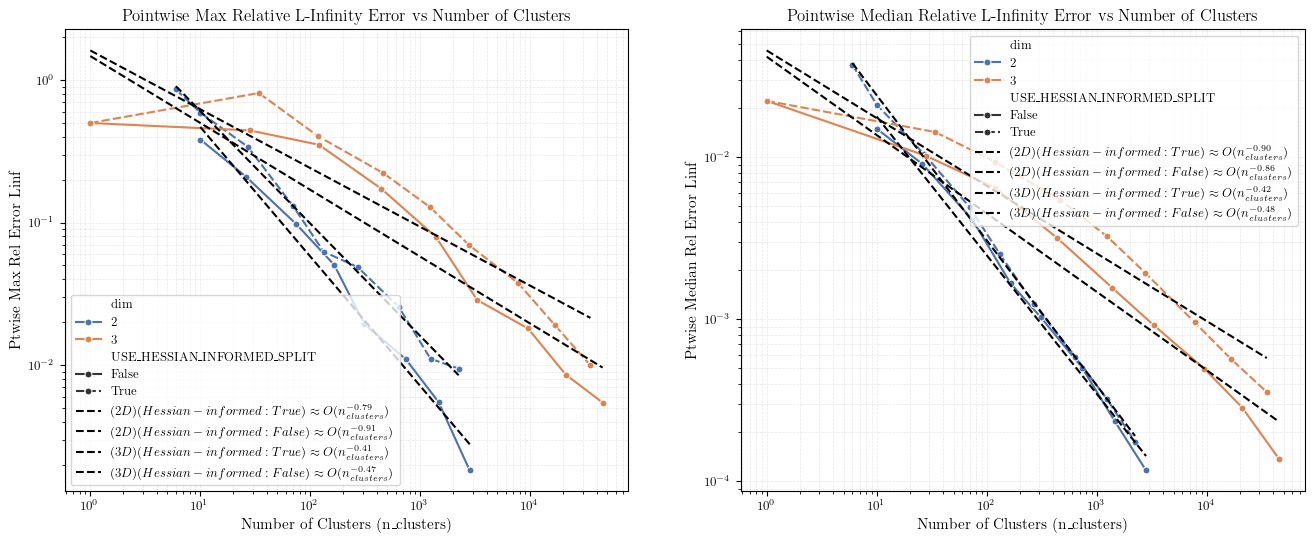

In [173]:
plot_error_with_log_log_fit(
    df_g,
    "l2_relative_error",
    "l2_abs_error",
    "L2 Relative Error vs Number of Clusters",
    "L2 Absolute Error vs Number of Clusters",
)

plot_error_with_log_log_fit(
    df_g,
    "ptwise_max_rel_error_linf",
    "ptwise_median_rel_error_linf",
    "Pointwise Max Relative L-Infinity Error vs Number of Clusters",
    "Pointwise Median Relative L-Infinity Error vs Number of Clusters",
)

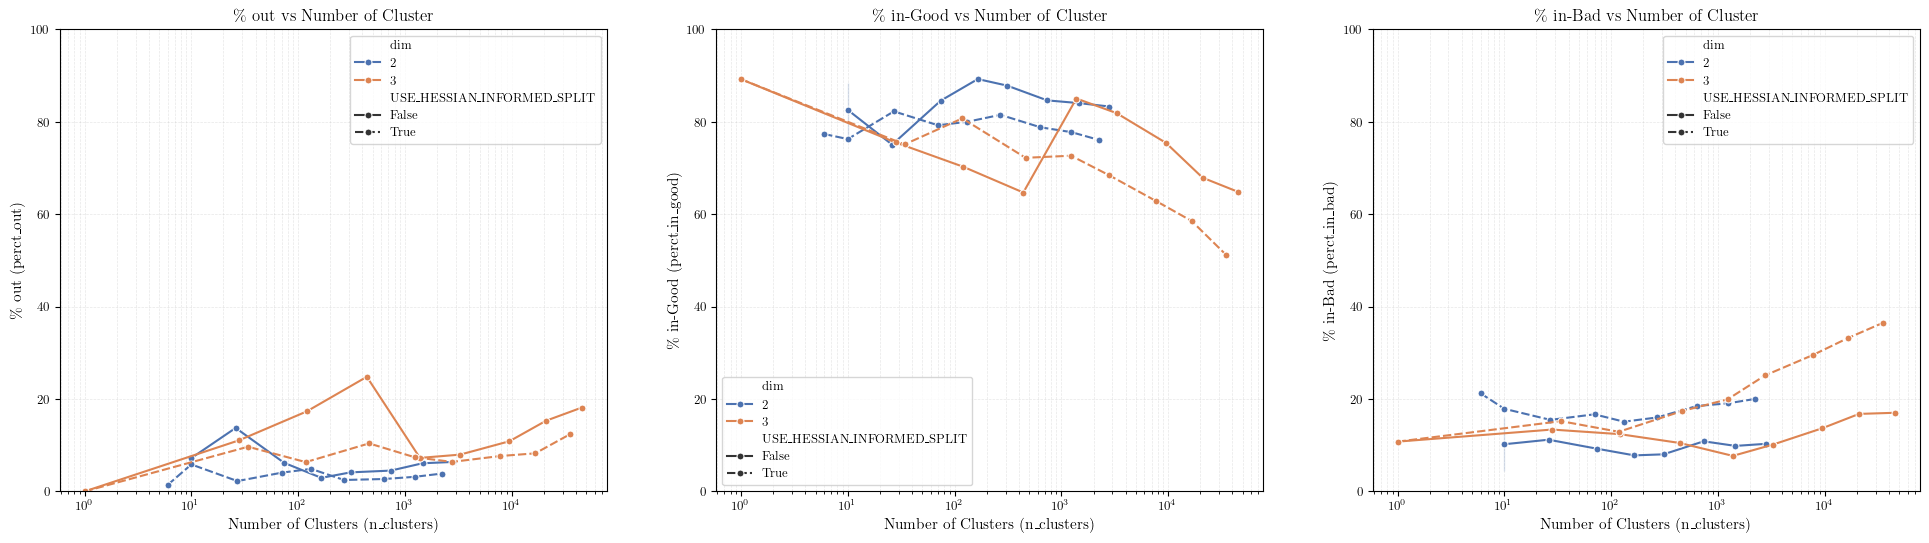

In [174]:
plt.figure(figsize=(24, 6))
plt.subplot(1, 3, 1)
sns.lineplot(
    data=df_g,
    x="n_clusters",
    y="perct_out",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ out (perct_out)")
plt.title(r"$\%$ out vs Number of Cluster")
plt.ylim(0, 100)
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 3, 2)
sns.lineplot(
    data=df_g,
    x="n_clusters",
    y="perct_in_good",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.ylim(0, 100)
plt.title(r"$\%$ in-Good vs Number of Cluster")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 3, 3)
sns.lineplot(
    data=df_g,
    x="n_clusters",
    y="perct_in_bad",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
plt.ylim(0, 100)
plt.title(r"$\%$ in-Bad vs Number of Cluster")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.show()

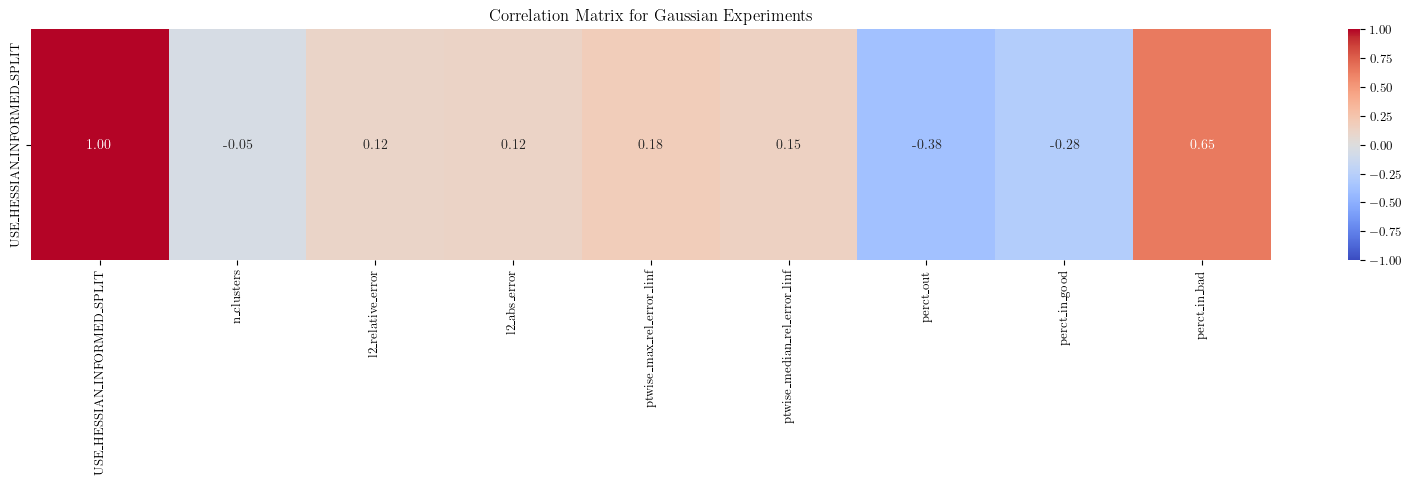

In [175]:
corr_cols = [
    "USE_HESSIAN_INFORMED_SPLIT",
    "n_clusters",
    "l2_relative_error",
    "l2_abs_error",
    "ptwise_max_rel_error_linf",
    "ptwise_median_rel_error_linf",
    "perct_out",
    "perct_in_good",
    "perct_in_bad",
]
corr_matrix = df_g[corr_cols].corr()
# Show only first row
corr_matrix = corr_matrix.loc[["USE_HESSIAN_INFORMED_SPLIT"], :]
plt.figure(figsize=(20, 3))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix for Gaussian Experiments")
plt.show()

In [176]:
rename_cols = {
    "dim": "D",
    "tol": "tol",
    "USE_HESSIAN_INFORMED_SPLIT": "Hessian-informed Split",
    "n_clusters": "N_src",
    "l2_relative_error": "L2 Rel Err",
    "l2_abs_error": "L2 Abs Err",
    "ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err",
    "ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err",
    "perct_out": "% Out",
    "perct_in_good": "% In-Good",
    "perct_in_bad": "% In-Bad",
    "n_train": "N_train",
    "n_test": "N_test",
}
df_g_renamed = df_g.rename(columns=rename_cols)[list(rename_cols.values())]
# Sort by D (asc), tol (desc)
df_g_renamed.sort_values(
    by=["D", "tol"],
    ascending=[True, False],
    inplace=True,
)
df_g_renamed.to_clipboard(index=False)

# Gaussian (Comparison vs Error Split Criterion)

In [177]:
gaussian_dir = (
    ICS26_DIR / "shifted_gaussians_with_ac_v1_hessian_informed_error_split_experiments"
)
csv_path = gaussian_dir / "summary.csv"

df_g = pd.read_csv(csv_path)

In [178]:
def plot_error_with_log_log_fit(df, error_col1, error_col2, title1, title2):
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue="dim",
        style="ERROR_SPLIT_CRITERION",
        size="USE_HESSIAN_INFORMED_SPLIT",
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for use_hessian in df["ERROR_SPLIT_CRITERION"].unique():
            subset = df[
                (df["dim"] == dim) & (df["ERROR_SPLIT_CRITERION"] == use_hessian)
            ]
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (Error Split Criterion: {use_hessian}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue="dim",
        style="ERROR_SPLIT_CRITERION",
        size="USE_HESSIAN_INFORMED_SPLIT",
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for use_hessian in df["ERROR_SPLIT_CRITERION"].unique():
            subset = df[
                (df["dim"] == dim) & (df["ERROR_SPLIT_CRITERION"] == use_hessian)
            ]
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (Error Split Criterion: {use_hessian}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

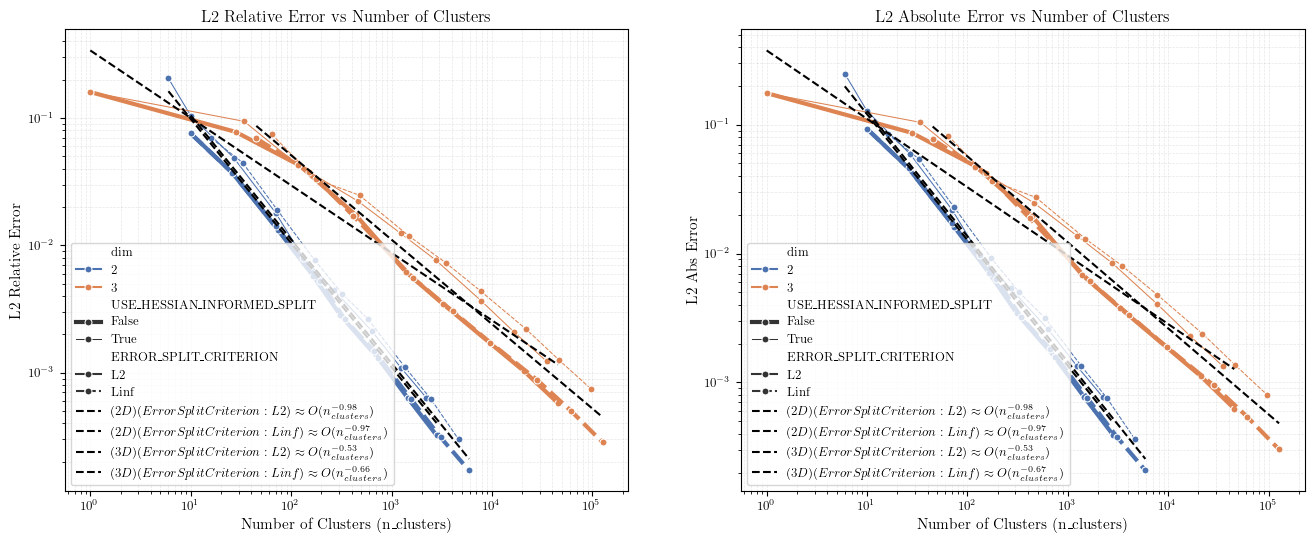

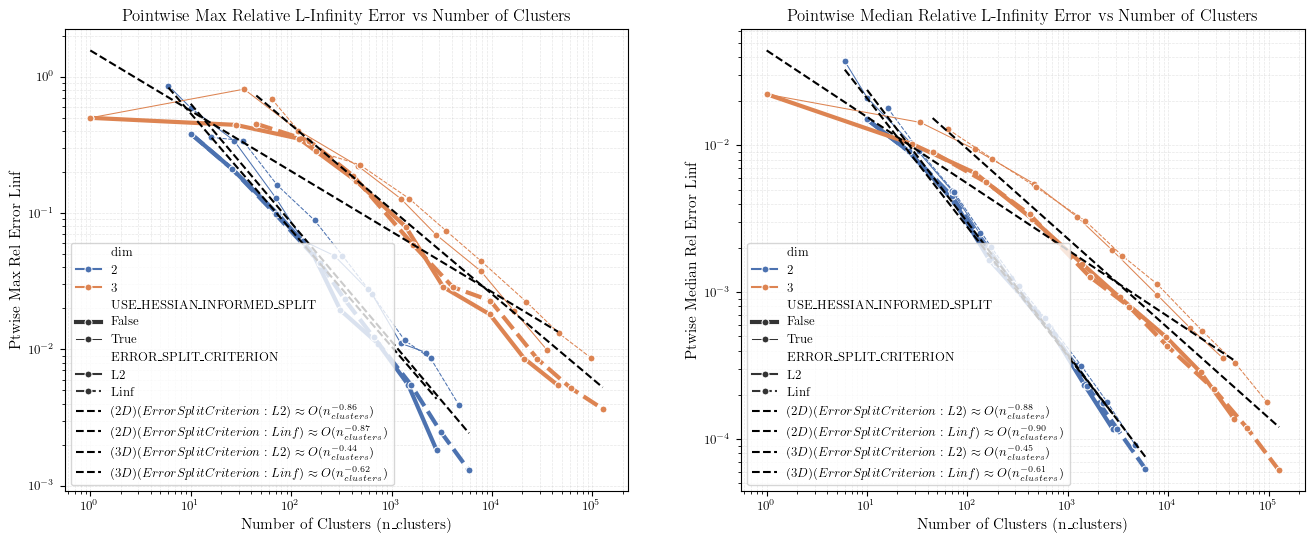

In [179]:
plot_error_with_log_log_fit(
    df_g,
    "l2_relative_error",
    "l2_abs_error",
    "L2 Relative Error vs Number of Clusters",
    "L2 Absolute Error vs Number of Clusters",
)

plot_error_with_log_log_fit(
    df_g,
    "ptwise_max_rel_error_linf",
    "ptwise_median_rel_error_linf",
    "Pointwise Max Relative L-Infinity Error vs Number of Clusters",
    "Pointwise Median Relative L-Infinity Error vs Number of Clusters",
)

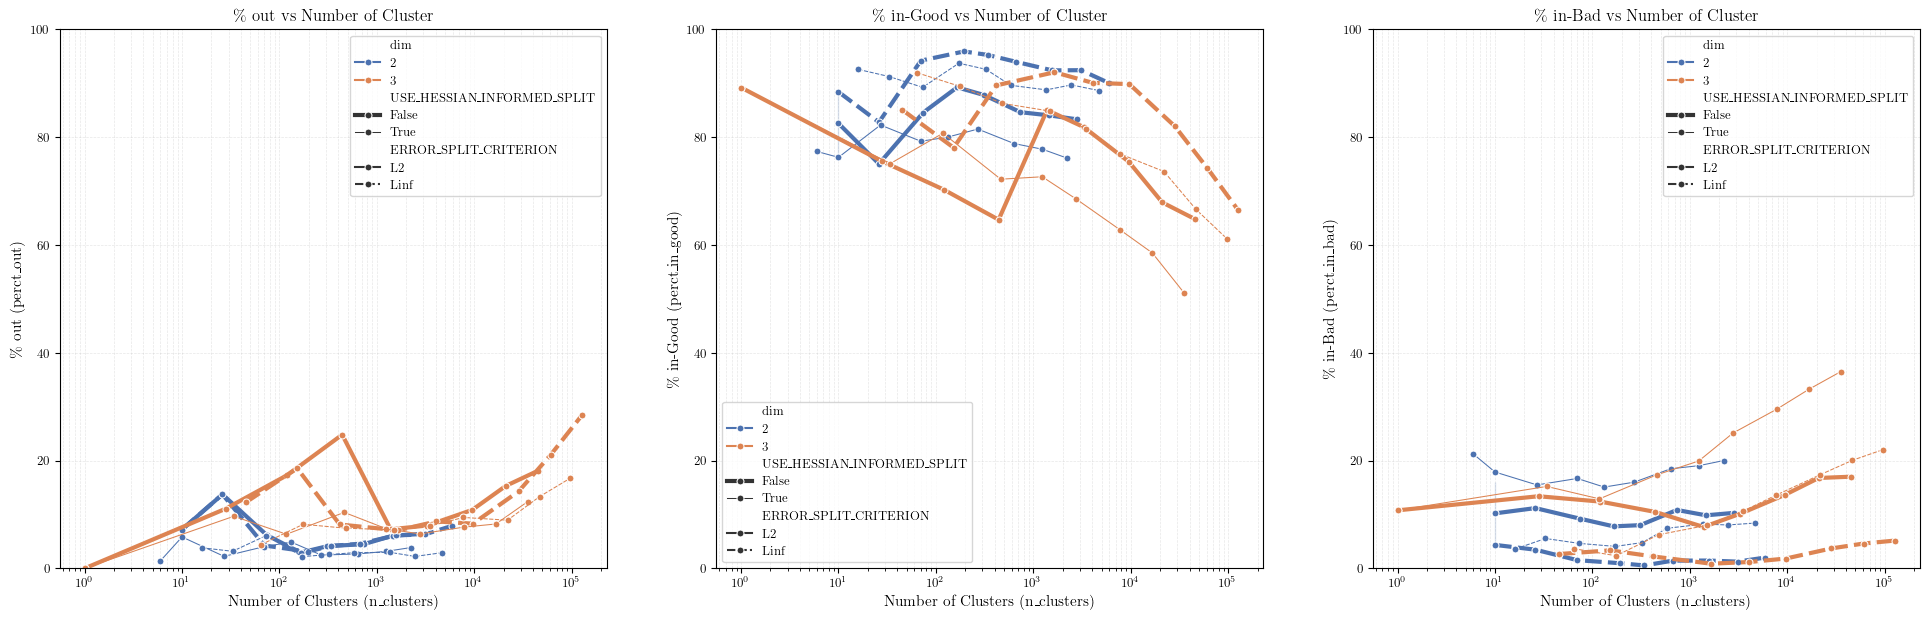

In [180]:
plt.figure(figsize=(24, 7))
plt.subplot(1, 3, 1)
sns.lineplot(
    data=df_g,
    x="n_clusters",
    y="perct_out",
    hue="dim",
    style="ERROR_SPLIT_CRITERION",
    size="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ out (perct_out)")
plt.title(r"$\%$ out vs Number of Cluster")
plt.ylim(0, 100)
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 3, 2)
sns.lineplot(
    data=df_g,
    x="n_clusters",
    y="perct_in_good",
    hue="dim",
    style="ERROR_SPLIT_CRITERION",
    size="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.ylim(0, 100)
plt.title(r"$\%$ in-Good vs Number of Cluster")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 3, 3)
sns.lineplot(
    data=df_g,
    x="n_clusters",
    y="perct_in_bad",
    hue="dim",
    style="ERROR_SPLIT_CRITERION",
    size="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
plt.ylim(0, 100)
plt.title(r"$\%$ in-Bad vs Number of Cluster")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.show()

In [181]:
rename_cols = {
    "dim": "D",
    "tol": "tol",
    "ERROR_SPLIT_CRITERION": "Error Split",
    "USE_HESSIAN_INFORMED_SPLIT": "Hessian-informed Split",
    "n_clusters": "N_src",
    "l2_relative_error": "L2 Rel Err",
    "l2_abs_error": "L2 Abs Err",
    "ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err",
    "ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err",
    "perct_out": "% Out",
    "perct_in_good": "% In-Good",
    "perct_in_bad": "% In-Bad",
    "n_train": "N_train",
    "n_test": "N_test",
}
df_g_renamed = df_g.rename(columns=rename_cols)[list(rename_cols.values())]
# Sort by Hess (asc), D (asc), tol (desc)
df_g_renamed.sort_values(
    by=["D", "tol"],
    ascending=[True, False],
    inplace=True,
)
df_g_renamed.to_clipboard(index=False)